# 04 · The forecast from today, and what-if scenarios

Notebooks 02-03 chose a method by backtest: **combo** (the average of a per-place ARIMA and a
rates-aware panel regression), added up from counties so every level agrees. This notebook runs it
from the last month of data and asks the questions a lender, insurer or investor would ask next:

1. **Baseline.** Where are home values heading over the next 12 months, at each level?
2. **Sanity check.** How does that compare with Zillow's own published forecast for the same month?
3. **Scenarios.** What if mortgage rates jump 1 or 2 points, fall 1 point, or a recession hits?
4. **Exposure.** Which metros take the biggest hit?

**How a scenario works.** It is a stress test in the catastrophe-model sense: *shock x exposure =
loss*. The **shock** is how the county panel regression's 12-month forecast moves when its rate
and unemployment inputs change. The **exposure** is each county's beta, its sensitivity to the
national cycle since 2009. Counties are then added up, so the nation, states and metros stay coherent.

| | |
|---|---|
| **Question** | What does the chosen model expect for the next 12 months, and how much would a rate shock change that? |
| **Answer** | From September 2026, the baseline is about 3% growth over 12 months for the panel's homes. Metros range from under 2% (bottom quarter) to over 4% (top quarter). That is about 1 pp above Zillow's own forecasts for the typical metro and 2 pp above for the nation, though the two agree on which metros grow faster (correlation 0.79). A sudden 1-point rise in mortgage rates cuts 12-month growth by 0.8-2.1 pp, depending on whether the pandemic years are in the training data. That is $0.45-1.2 trillion of housing value. The hit is about four times larger in high-beta Sun Belt metros (Las Vegas -4.2 pp, Phoenix -3.8 pp) than in Rust Belt and Northeast metros (Pittsburgh -1.0 pp). |
| **Next** | The [decision memo](../reports/decision_memo.md) turns this into a recommendation. |

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from housing import backtest as bt
from housing import checks, models, panel, scenarios
from housing.config import data_dirs, use_synthetic
from housing.plots import COLORS, save, style, write_metrics

style()
if use_synthetic():
    print("SYNTHETIC DATA: numbers below are made up (CI run).")
proc = data_dirs()[1]
Y, S_df, tags, nodes = panel.load_hierarchy()
L = bt.log_wide(Y)[list(S_df["unique_id"])]
F = models.features(L, panel.load_macro(), pd.read_parquet(proc / "state_unemp.parquet"), nodes)
now = scenarios.forecast_now(L, F, tags)
origin = now["origin"]
y0 = np.exp(L.iloc[-1])
hu = Y.drop_duplicates("unique_id").set_index("unique_id")["hu"].reindex(L.columns)
counties = list(S_df.columns[1:])
beta = scenarios.county_betas(L, counties, weights=hu)
base_vals = scenarios.apply(now["combo"], S_df, y0, beta, pd.Series(0.0, index=scenarios.PATH_H))
print(f"Forecast date: {origin:%B %Y}; horizons 1-12 months; {len(counties):,} counties")

Forecast date: September 2026; horizons 1-12 months; 1,371 counties


## 1. Baseline: the next 12 months

Growth of the typical home value (housing-stock value / housing units), coherent across levels.
The band around the national path is the 10th-90th percentile of the method's own past national
errors at each horizon, from the notebook-03 backtest. Notebook 03 showed such bands run narrow at
turning points, so read it as the *least* uncertainty to expect.

In [2]:
g12 = np.log(base_vals[12] / y0.reindex(base_vals.index))
lv = checks.level_of(pd.Series(g12.index))
summary = (100 * g12).groupby(lv.to_numpy()).describe()[["count", "25%", "50%", "75%"]].reindex(
    ["National", "State", "Metro", "County"])
summary.columns = ["nodes", "p25 (%)", "median (%)", "p75 (%)"]
write_metrics("04_baseline_by_level", summary.reset_index(names="level"))
summary.round(2)

,nodes,p25 (%),median (%),p75 (%)
National,1.0,3.13,3.13,3.13
State,49.0,2.39,3.18,3.86
Metro,605.0,1.95,3.20,4.19
County,1371.0,1.84,3.14,4.29


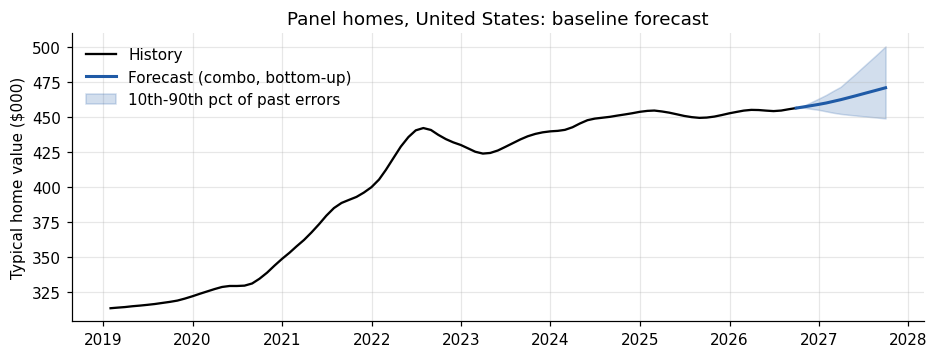

In [3]:
bt_path = proc / "backtest_models.parquet"
if bt_path.exists() and not use_synthetic():
    errs = pd.read_parquet(bt_path, filters=[("method", "==", "combo+bottom_up"), ("unique_id", "==", "US")])
else:
    from housing.pipeline import run_all
    r = run_all(save=False)["long"]
    errs = r[(r["method"] == "combo+bottom_up") & (r["unique_id"] == "US")]
errs = errs.assign(err=errs["pred"] - errs["actual"])
q = errs.groupby("h")["err"].quantile([0.1, 0.9]).unstack()
q = q.reindex(range(0, 13)).interpolate(limit_direction="both").fillna(0)
q.loc[0] = 0

hist = Y[Y["unique_id"] == "US"].set_index("ds")["typical_value"]
path = pd.Series(np.r_[y0["US"], base_vals.loc["US"].to_numpy()] / hu["US"],
                 index=pd.date_range(origin, periods=13, freq="ME"))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(hist.loc["2019":].index, hist.loc["2019":] / 1e3, color="k", lw=1.5, label="History")
ax.plot(path.index, path / 1e3, color=COLORS["ours"], lw=2, label="Forecast (combo, bottom-up)")
ax.fill_between(path.index, path * np.exp(-q[0.9].to_numpy()) / 1e3, path * np.exp(-q[0.1].to_numpy()) / 1e3,
                color=COLORS["ours"], alpha=0.2, label="10th-90th pct of past errors")
ax.set_ylabel("Typical home value ($000)")
ax.set_title("Panel homes, United States: baseline forecast")
ax.legend(frameon=False)
save(fig, "04_us_baseline")

Largest metros, 12-month baseline growth:

In [4]:
metros = [u for u in tags["Metro"] if "Non-metro" not in u]
big = hu.reindex(metros).nlargest(20).index
top = pd.DataFrame({"housing units": hu[big], "12-month growth (%)": 100 * g12[big]})
top.index = top.index.str[4:]
top.round({"12-month growth (%)": 2})

,housing units,12-month growth (%)
unique_id,,
"New York, NY",8186305.0,3.76
"Los Angeles, CA",4893955.0,3.34
"Chicago, IL",3976420.0,5.03
"Houston, TX",3015306.0,1.79
"Dallas, TX",2896153.0,2.27
"Miami, FL",2729087.0,3.64
"Philadelphia, PA",2660296.0,3.98
"Washington, DC",2524797.0,2.25
"Atlanta, GA",2486122.0,1.46


## 2. Sanity check against Zillow's own forecast

Zillow published its metro forecast (ZHVF) from the same month. Two differences to keep in mind:
Zillow forecasts its index for *all* homes in a metro, while this model covers the metro's counties
with a full history; and Zillow's forecast uses listing and demand data this project does not have.
The check is for broad agreement, not equality. Only metros where the panel holds at least 95% of the
housing units are compared.

In [5]:
zf = pd.read_parquet(proc / "zhvf_metro.parquet")
z12 = zf[zf["horizon"] == 12].copy()
z12["unique_id"] = np.where(z12["region_type"].str.lower() == "country", "US", "MSA:" + z12["region"])
cov = pd.read_parquet(proc / "coverage.parquet").set_index("unique_id")["hu_coverage"]
cmp_ = z12.set_index("unique_id")[["growth_pct", "base"]].join(
    (100 * (np.exp(g12) - 1)).rename("ours_pct")).join(cov).dropna()
cmp_ = cmp_[(cmp_["hu_coverage"] >= 0.95) | (cmp_.index == "US")]
same_month = bool((cmp_["base"] == origin).all())
corr = cmp_.drop(index="US", errors="ignore")[["growth_pct", "ours_pct"]].corr().iloc[0, 1]
gap = (cmp_["ours_pct"] - cmp_["growth_pct"]).drop(index="US", errors="ignore")
zsum = {"zillow_base_month": str(cmp_["base"].iloc[0].date()) if len(cmp_) else None, "same_month": same_month,
        "metros_compared": int((cmp_.index != "US").sum()), "correlation": float(corr),
        "median_gap_pp": float(gap.median()), "mean_abs_gap_pp": float(gap.abs().mean()),
        "us_zillow_pct": float(cmp_.loc["US", "growth_pct"]) if "US" in cmp_.index else None,
        "us_ours_pct": float(cmp_.loc["US", "ours_pct"]) if "US" in cmp_.index else None}
write_metrics("04_vs_zillow_forecast", zsum)
write_metrics("04_vs_zillow_forecast_metros", cmp_.reset_index())
pd.Series(zsum)

zillow_base_month    2026-09-30
same_month                 True
metros_compared             439
correlation            0.787291
median_gap_pp          1.181593
mean_abs_gap_pp        1.383324
us_zillow_pct               1.1
us_ours_pct              3.1769
dtype: object

**Reading the comparison.** The two forecasts rank metros alike, but this model sits higher: about
1 pp above Zillow for the typical metro and 2 pp above for the nation. Likely reasons: the smoothed
index carries recent momentum forward; the panel leaves out the rural counties in Zillow's national
figure; and Zillow sees listings, demand and inventory, which this model does not. For a decision, a
reasonable split is to take the *level* from the more conservative forecast, and the *ranking* and
*rate sensitivity* from this one, which is the part it was built and backtested to deliver.

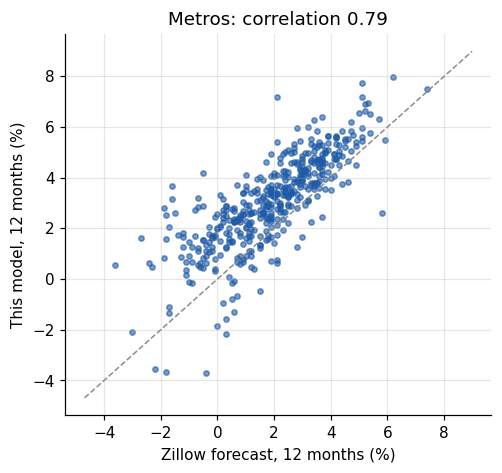

In [6]:
m = cmp_.drop(index="US", errors="ignore")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(m["growth_pct"], m["ours_pct"], s=12, alpha=0.6, color=COLORS["ours"])
lim = [min(m[["growth_pct", "ours_pct"]].min()) - 1, max(m[["growth_pct", "ours_pct"]].max()) + 1]
ax.plot(lim, lim, color=COLORS["grey"], ls="--", lw=1)
ax.set_xlabel("Zillow forecast, 12 months (%)")
ax.set_ylabel("This model, 12 months (%)")
ax.set_title(f"Metros: correlation {corr:.2f}")
save(fig, "04_vs_zillow")

## 3. Scenarios

The shock comes from the county panel regression. Two versions of it are shown, because one input
depends heavily on a single episode:
* **full sample**: the model as backtested;
* **pandemic left out**: refitted without training targets in March 2020 - December 2021, when
  unemployment spiked while prices boomed. On the full sample, higher unemployment *raises* the
  forecast, which is that episode talking. Without it, the unemployment effect is close to zero and
  the rate effect is smaller.

The gap between the two columns is model uncertainty, and the memo quotes the range rather than one number.

In [7]:
coef_tab = pd.concat({k: v.loc[["d_rate12", "rate_gap", "d_unemp12"], [3, 12]] for k, v in now["county_coefs"].items()},
                     axis=1)
write_metrics("04_scenario_coefficients", coef_tab.reset_index(names="feature"))
coef_tab.round(4)

full sample         pandemic left out        
                   3       12                3       12
d_rate12      -0.0018 -0.0042           -0.0026 -0.0024
rate_gap      -0.0016 -0.0163            0.0006 -0.0051
d_unemp12      0.0005  0.0050           -0.0006  0.0008

In [8]:
us_total0 = y0["US"]
rows, paths = [], {}
for version, coefs in now["county_coefs"].items():
    for name, deltas in scenarios.SCENARIOS.items():
        shock = scenarios.shock_path(coefs, deltas)
        vals = scenarios.apply(now["combo"], S_df, y0, beta, shock)
        d12 = np.log(vals.loc["US", 12] / base_vals.loc["US", 12])
        rows.append({"scenario": name, "coefficients": version,
                     "US 12-month growth (%)": 100 * (vals.loc["US", 12] / us_total0 - 1),
                     "vs baseline (pp)": 100 * d12,
                     "value change vs baseline ($bn)": (vals.loc["US", 12] - base_vals.loc["US", 12]) / 1e9})
        if version == "full sample":
            paths[name] = vals.loc["US"] / hu["US"]
scen = pd.DataFrame(rows)
base_row = {"scenario": "Baseline", "coefficients": "-", "US 12-month growth (%)": 100 * (base_vals.loc["US", 12]
            / us_total0 - 1), "vs baseline (pp)": 0.0, "value change vs baseline ($bn)": 0.0}
scen = pd.concat([pd.DataFrame([base_row]), scen], ignore_index=True)
write_metrics("04_scenarios", scen)
scen.round(2)

,scenario,coefficients,US 12-month growth (%),vs baseline (pp),value change vs baseline ($bn)
0,Baseline,-,3.18,0.00,0.00
1,Rates +1 pt,full sample,1.01,-2.13,-1233.05
2,Rates +2 pt (stress),full sample,-1.11,-4.24,-2436.70
3,Rates -1 pt,full sample,5.40,2.13,1263.24
4,"Recession (unemployment +3, rates -1)",full sample,7.08,3.71,2218.58
5,Rates +1 pt,pandemic left out,2.38,-0.78,-454.25
6,Rates +2 pt (stress),pandemic left out,1.59,-1.55,-904.50
7,Rates -1 pt,pandemic left out,3.98,0.78,458.28
8,"Recession (unemployment +3, rates -1)",pandemic left out,4.26,1.04,613.74


**The recession row is not a forecast of a recession.** The model is linear, and over 2010-2026
rate cuts went with rising prices while unemployment did little on its own (pandemic left out). So
"unemployment +3, rates -1" comes out *positive*. A 2008-style recession, with forced selling and
tight credit, is outside what this training period can represent. The memo treats the rate scenarios
as the usable stress tests.

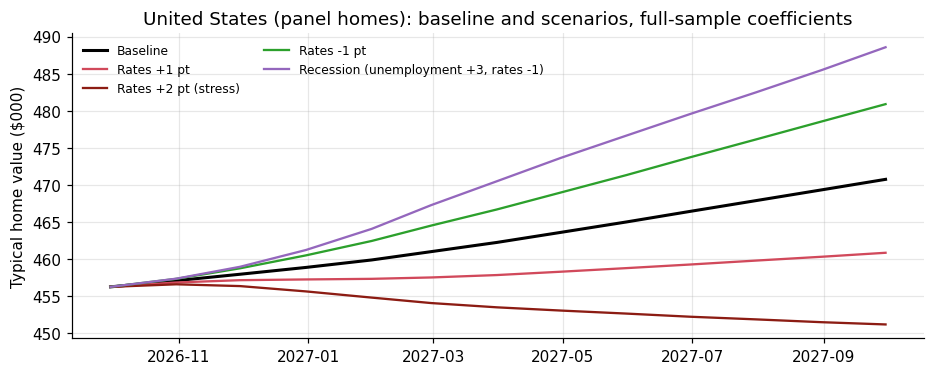

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.6))
idx = pd.date_range(origin, periods=13, freq="ME")
start = y0["US"] / hu["US"]
ax.plot(idx, np.r_[start, base_vals.loc["US"] / hu["US"]] / 1e3, color="k", lw=2, label="Baseline")
pal = ["#d1495b", "#8c1c13", "#2ca02c", "#9467bd"]
for (name, p), c in zip(paths.items(), pal):
    ax.plot(idx, np.r_[start, p] / 1e3, color=c, lw=1.5, label=name)
ax.set_ylabel("Typical home value ($000)")
ax.set_title("United States (panel homes): baseline and scenarios, full-sample coefficients")
ax.legend(frameon=False, fontsize=8, ncol=2)
save(fig, "04_us_scenarios")

## 4. Exposure: which metros take the biggest hit from a 1-point rate rise?

Same shock everywhere, scaled by each county's beta. High-beta places are the ones that boomed
hardest in 2020-22 and fell hardest in 2008-11.

In [10]:
shock1 = scenarios.shock_path(now["county_coefs"]["full sample"], scenarios.SCENARIOS["Rates +1 pt"])
v1 = scenarios.apply(now["combo"], S_df, y0, beta, shock1)
hit = 100 * np.log(v1[12] / base_vals[12])
shock2 = scenarios.shock_path(now["county_coefs"]["full sample"], scenarios.SCENARIOS["Rates +2 pt (stress)"])
v2 = scenarios.apply(now["combo"], S_df, y0, beta, shock2)
hit2 = np.log(v2[12] / base_vals[12])
zil = z12.set_index("unique_id")["growth_pct"]
metro_beta = (beta * hu.reindex(beta.index)).groupby(nodes.set_index("County")["Metro"].reindex(beta.index)).sum() / \
    hu.reindex(beta.index).groupby(nodes.set_index("County")["Metro"].reindex(beta.index)).sum()
big50 = hu.reindex(metros).nlargest(50).index
exp_tab = pd.DataFrame({"housing units": hu[big50], "beta": metro_beta.reindex(big50),
                        "baseline 12m (%)": 100 * g12[big50], "rates +1: change (pp)": hit[big50],
                        "rates +1: value change ($bn)": (v1[12] - base_vals[12])[big50] / 1e9,
                        "Zillow 12m (%)": zil.reindex(big50),
                        # conservative stress: Zillow's level, this model's +2 pt shock for the metro
                        "Zillow + rates +2 (%)": 100 * ((1 + zil.reindex(big50) / 100) * np.exp(hit2[big50]) - 1)})
exp_tab.index = exp_tab.index.str[4:]
exp_tab = exp_tab.sort_values("rates +1: change (pp)")
write_metrics("04_metro_exposure", exp_tab.reset_index(names="metro"))
exp_tab.head(10).round(2)

,housing units,beta,baseline 12m (%),rates +1: change (pp),rates +1: value change ($bn),Zillow 12m (%),Zillow + rates +2 (%)
unique_id,,,,,,,
"Las Vegas, NV",989890.0,2.07,2.57,-4.23,-17.78,-1.5,-9.49
"Phoenix, AZ",2209356.0,1.85,1.55,-3.77,-37.05,-1.8,-8.93
"Cape Coral, FL",479540.0,1.78,0.57,-3.64,-5.77,-3.6,-10.37
"Riverside, CA",1661044.0,1.75,2.84,-3.57,-34.59,0.3,-6.60
"Orlando, FL",1219531.0,1.70,2.67,-3.48,-16.60,-0.8,-7.47
"Miami, FL",2729087.0,1.63,3.64,-3.33,-44.40,0.7,-5.80
"Tampa, FL",1583122.0,1.63,2.02,-3.33,-19.07,-1.7,-8.04
"North Port, FL",531195.0,1.59,2.78,-3.24,-7.03,-1.9,-8.06
"Sacramento, CA",986646.0,1.51,1.67,-3.06,-17.35,-0.8,-6.70


**A conservative stress view.** The baseline here sits above Zillow's (section 2), so the last
column takes Zillow's own 12-month forecast as the starting level and applies this model's
+2-point rate shock for each metro. Metros where that column is negative are where a lender or
investor could see values *fall* over the next year under stress.

In [11]:
falls = exp_tab[exp_tab["Zillow + rates +2 (%)"] < 0].sort_values("Zillow + rates +2 (%)")
write_metrics("04_stress_falls", {"metros_of_50_falling": int(len(falls)), "metros_with_zillow_forecast": int(exp_tab["Zillow 12m (%)"].notna().sum()),
                                  "falling": falls["Zillow + rates +2 (%)"].round(2).to_dict()})
falls[["beta", "Zillow 12m (%)", "rates +1: change (pp)", "Zillow + rates +2 (%)"]].round(2)

,beta,Zillow 12m (%),rates +1: change (pp),Zillow + rates +2 (%)
unique_id,,,,
"Cape Coral, FL",1.78,-3.6,-3.64,-10.37
"Las Vegas, NV",2.07,-1.5,-4.23,-9.49
"Phoenix, AZ",1.85,-1.8,-3.77,-8.93
"North Port, FL",1.59,-1.9,-3.24,-8.06
"Tampa, FL",1.63,-1.7,-3.33,-8.04
"Orlando, FL",1.70,-0.8,-3.48,-7.47
"Austin, TX",1.16,-2.4,-2.38,-6.94
"Sacramento, CA",1.51,-0.8,-3.06,-6.70
"Riverside, CA",1.75,0.3,-3.57,-6.60


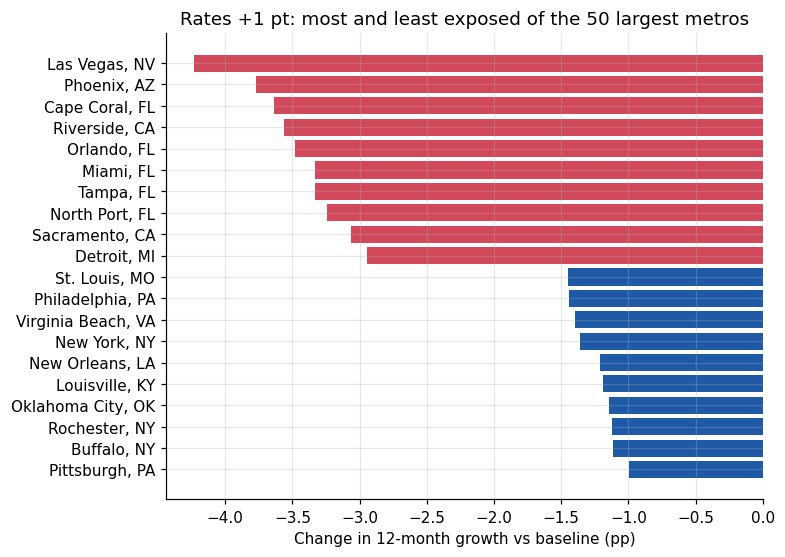

In [12]:
sel = pd.concat([exp_tab.head(10), exp_tab.tail(10)])
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(sel.index[::-1], sel["rates +1: change (pp)"][::-1],
        color=[COLORS["zillow"] if v < sel["rates +1: change (pp)"].median() else COLORS["ours"]
               for v in sel["rates +1: change (pp)"][::-1]])
ax.set_xlabel("Change in 12-month growth vs baseline (pp)")
ax.set_title("Rates +1 pt: most and least exposed of the 50 largest metros")
save(fig, "04_metro_exposure")

## 5. Limits of these scenarios
* **One model carries the shock.** ar2 has no view on rates, so the shift comes from the panel
  regression alone, applied in full on top of the combined baseline.
* **Linear and immediate.** The shock is a straight-line response to a change seen at the forecast
  date. It has no feedback (prices do not move rates back) and nothing about how long the shock lasts.
* **Associations, not causes.** The coefficients are what usually followed such rate moves in
  2010-2026, a period dominated by one boom and one rate shock. The two coefficient versions show
  how much a single episode can move them.
* **Beta is history.** A place's past sensitivity to the national cycle stands in for its exposure.
  Places whose economy has changed since 2009 will be mis-scaled.